# NOVA B03 · Mixture-of-Experts models

Trains three MoE variants with the same active compute as the dense baseline and compares them: experts are half the width of the dense feed-forward layer and each token uses the top 2 of 8 experts, so 88.1M of the 130.6M parameters are active per token.

| Run | Expert layers | Load balancing | Best val loss | Perplexity |
|---|---|---|---|---|
| dense (B02) | none | - | 3.3950 | 29.82 |
| moe | blocks 3, 7, 11 | yes | **3.3600** | **28.79** |
| moe_nobal | blocks 3, 7, 11 | no | 3.3680 | 29.02 |
| moe_early | blocks 1, 2, 5 | yes | 3.3628 | 28.87 |

## Hardware
Confirms the GPU and the PyTorch build used for this notebook (NVIDIA RTX 5050 Laptop GPU, 8 GB).

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch; print('torch', torch.__version__, '| cuda available:', torch.cuda.is_available())

name, memory.total [MiB]
NVIDIA GeForce RTX 5050 Laptop GPU, 8151 MiB
torch 2.11.0+cu128 | cuda available: True


## Dependencies
Python packages required by this notebook in addition to PyTorch.

In [2]:
!pip install -q tokenizers

## Model (`model.py`)
Same model file as B02; the MoE layer replaces the feed-forward network in the selected blocks.

In [3]:
%%writefile model.py
"""
Team NOVA - AFML Project
model.py: our own decoder-only transformer, with an optional Mixture-of-Experts FFN.

Differences from the video (GPT-2 style) model, and why:
  * RMSNorm instead of LayerNorm  - no mean-centering, fewer ops, equally stable (LLaMA)
  * RoPE instead of learned position embeddings - relative positions via rotating Q and K
  * SwiGLU feed-forward instead of GELU MLP     - gated FFN, lower loss at equal params
  * No bias terms                                - fewer params, no quality loss at this scale
  * Weight tying (kept from GPT-2)               - input embedding = output projection
  * MoE switch: any layer listed in config.moe_layers uses MoEFFN instead of SwiGLU.
    With moe_layers = () the model is a plain dense transformer (Phase 1).
  * Optional (used by the Base model on C4, off for the small model):
      - Grouped-query attention (n_kv_head < n_head): several query heads share one key/value head
        (LLaMA-2 70B, LLaMA-3, Mistral). Fewer parameters and a 3x smaller KV cache, same quality.
      - QK-norm (qk_norm=True): RMSNorm on each query and key head before RoPE (OLMo-2, Qwen3,
        Gemma-3). Keeps attention logits bounded, which matters in float16 on a T4.

Shapes: B = batch, T = sequence length, C = n_embd, H = n_head, D = head size, V = vocab.
"""

import math
from dataclasses import dataclass, field

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class ModelConfig:
    vocab_size: int = 8192
    block_size: int = 256          # max context length T
    n_layer: int = 6
    n_head: int = 6                # query heads H
    n_kv_head: int = 0             # key/value heads; 0 means = n_head (ordinary multi-head attention)
    qk_norm: bool = False          # RMSNorm on q and k per head
    n_embd: int = 384              # C
    ffn_hidden: int = 1024         # SwiGLU hidden size (~ 8/3 * C, rounded)
    dropout: float = 0.0           # each training token is seen about once, so no dropout
    rope_theta: float = 10000.0
    # --- Mixture of Experts (Phase 2). Empty tuple = dense model. ---
    moe_layers: tuple = ()         # e.g. (1, 3, 5) = MoE in alternate layers
    n_experts: int = 8
    top_k: int = 2
    expert_hidden: int = 512       # each expert is half the dense FFN width


# ----------------------------------------------------------------------------
# Building blocks
# ----------------------------------------------------------------------------
class RMSNorm(nn.Module):
    """y = x / sqrt(mean(x^2) + eps) * g.  Like LayerNorm but without subtracting the mean."""

    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        # compute in float32 for stability under mixed precision
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return xf.type_as(x) * self.weight


def build_rope_cache(T, D, theta, device):
    """Precompute cos/sin for rotary embeddings. Returns two (T, D/2) tensors."""
    inv_freq = 1.0 / (theta ** (torch.arange(0, D, 2, device=device).float() / D))  # (D/2,)
    t = torch.arange(T, device=device).float()                                       # (T,)
    freqs = torch.outer(t, inv_freq)                                                 # (T, D/2)
    return freqs.cos(), freqs.sin()


def apply_rope(x, cos, sin):
    """Rotate each pair (x1, x2) of features by an angle that depends on the position.

    x: (B, H, T, D). Pairing: first half of D with second half.
    After rotation, q·k depends only on the RELATIVE distance between positions.
    """
    D = x.shape[-1]
    x1, x2 = x[..., : D // 2], x[..., D // 2 :]
    cos, sin = cos[None, None], sin[None, None]          # (1, 1, T, D/2)
    return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)


class CausalSelfAttention(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0
        self.n_head = cfg.n_head
        self.n_kv_head = cfg.n_kv_head or cfg.n_head                    # Hkv
        assert self.n_head % self.n_kv_head == 0, "query heads must split evenly into KV groups"
        self.head_dim = cfg.n_embd // cfg.n_head                        # D
        self.kv_dim = self.n_kv_head * self.head_dim                    # Hkv * D (= C without GQA)
        self.qkv = nn.Linear(cfg.n_embd, cfg.n_embd + 2 * self.kv_dim, bias=False)  # C -> C + 2*Hkv*D
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=False)      # C -> C
        if cfg.qk_norm:
            self.q_norm, self.k_norm = RMSNorm(self.head_dim), RMSNorm(self.head_dim)
        else:
            self.q_norm = self.k_norm = None
        self.dropout = cfg.dropout

    def forward(self, x, cos, sin):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split([C, self.kv_dim, self.kv_dim], dim=2)  # (B,T,C), 2 x (B,T,Hkv*D)
        # (B, T, C) -> (B, H, T, D); keys and values have Hkv heads
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        if self.q_norm is not None:                                     # QK-norm, before RoPE
            q, k = self.q_norm(q), self.k_norm(k)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        if self.n_kv_head != self.n_head:                               # GQA: each KV head serves
            rep = self.n_head // self.n_kv_head                         # n_head / n_kv_head query heads
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        # softmax(q k^T / sqrt(D) + causal mask) v, computed by a fused kernel
        y = F.scaled_dot_product_attention(
            q, k, v, is_causal=True, dropout_p=self.dropout if self.training else 0.0
        )                                                               # (B, H, T, D)
        y = y.transpose(1, 2).contiguous().view(B, T, C)                # (B, T, C)
        return self.proj(y)


class SwiGLU(nn.Module):
    """FFN(x) = W_down( SiLU(W_gate x) * (W_up x) ).  Applied to each token independently."""

    def __init__(self, n_embd, hidden):
        super().__init__()
        self.gate = nn.Linear(n_embd, hidden, bias=False)
        self.up = nn.Linear(n_embd, hidden, bias=False)
        self.down = nn.Linear(hidden, n_embd, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))


class MoEFFN(nn.Module):
    """Top-k Mixture of Experts feed-forward layer (Phase 2).

    router:  logits z = W_r h            (one score per expert, per token)
    select:  the top_k experts by z
    combine: y = sum_{i in top-k} g_i * Expert_i(h),  g = softmax over the top-k logits

    Also returns:
      aux_loss  - Switch-Transformer load-balancing loss  E * sum_i f_i * P_i
      z_loss    - mean(logsumexp(z)^2), keeps router logits small and stable
      routing   - dict with logits / chosen experts, used by the research analysis
    """

    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.n_experts = cfg.n_experts
        self.top_k = cfg.top_k
        self.router = nn.Linear(cfg.n_embd, cfg.n_experts, bias=False)
        self.experts = nn.ModuleList(
            [SwiGLU(cfg.n_embd, cfg.expert_hidden) for _ in range(cfg.n_experts)]
        )
        # Research hook (Phase 6, counterfactual routing). Not a parameter, never saved.
        # Set to (mask, idx): mask (N,) bool marks tokens to override, idx (N, k) their forced experts.
        self.force_route = None

    def forward(self, x, valid=None):
        """valid: optional (B, T) bool mask; padding tokens (False) are left out of the balancing
        statistics (aux loss, z-loss). They are still routed, which does not affect real tokens
        because causal attention never lets a real token see the padding after it."""
        B, T, C = x.shape
        h = x.reshape(-1, C)                                            # (N, C), N = B*T
        logits = self.router(h).float()                                 # (N, E)
        probs = logits.softmax(dim=-1)                                  # (N, E)
        top_logits, top_idx = logits.topk(self.top_k, dim=-1)           # (N, k)
        if self.force_route is not None:                                # counterfactual: force experts
            mask, forced = self.force_route
            top_idx = torch.where(mask[:, None], forced, top_idx)
            top_logits = logits.gather(1, top_idx)                      # gates from the forced experts
        gates = top_logits.softmax(dim=-1).type_as(h)                   # (N, k), renormalized

        out = torch.zeros_like(h)
        for e in range(self.n_experts):
            token_pos, slot = (top_idx == e).nonzero(as_tuple=True)     # tokens routed to e
            if token_pos.numel() == 0:
                continue
            y = self.experts[e](h[token_pos])                           # (n_e, C)
            out.index_add_(0, token_pos, y * gates[token_pos, slot, None])

        # load balancing: f_i = fraction of routing slots sent to expert i,
        #                 P_i = mean router probability of expert i
        v = torch.ones(h.shape[0], device=h.device) if valid is None else valid.reshape(-1).float()
        n_valid = v.sum().clamp(min=1.0)
        f = torch.zeros(self.n_experts, device=h.device)
        f.scatter_add_(0, top_idx.reshape(-1), v.repeat_interleave(self.top_k))
        f = f / (n_valid * self.top_k)
        P = (probs * v[:, None]).sum(dim=0) / n_valid
        aux_loss = self.n_experts * (f * P).sum()
        z_loss = (torch.logsumexp(logits, dim=-1).pow(2) * v).sum() / n_valid

        routing = {"logits": logits.detach(), "top_idx": top_idx.detach()}
        return out.view(B, T, C), aux_loss, z_loss, routing


class Block(nn.Module):
    """Pre-norm transformer block:  x = x + attn(norm(x));  x = x + ffn(norm(x))."""

    def __init__(self, cfg: ModelConfig, layer_idx: int):
        super().__init__()
        self.norm1 = RMSNorm(cfg.n_embd)
        self.attn = CausalSelfAttention(cfg)
        self.norm2 = RMSNorm(cfg.n_embd)
        self.is_moe = layer_idx in cfg.moe_layers
        self.ffn = MoEFFN(cfg) if self.is_moe else SwiGLU(cfg.n_embd, cfg.ffn_hidden)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, cos, sin, valid=None):
        x = x + self.drop(self.attn(self.norm1(x), cos, sin))
        if self.is_moe:
            y, aux, z, routing = self.ffn(self.norm2(x), valid)
            return x + self.drop(y), aux, z, routing
        return x + self.drop(self.ffn(self.norm2(x))), None, None, None


# ----------------------------------------------------------------------------
# The full model
# ----------------------------------------------------------------------------
class NovaLM(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.blocks = nn.ModuleList([Block(cfg, i) for i in range(cfg.n_layer)])
        self.norm_f = RMSNorm(cfg.n_embd)
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight                      # weight tying

        cos, sin = build_rope_cache(cfg.block_size, cfg.n_embd // cfg.n_head, cfg.rope_theta, "cpu")
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

        self.apply(self._init_weights)
        # scale down the layers that write into the residual stream (GPT-2 trick):
        # each block adds 2 contributions, so std / sqrt(2 * n_layer) keeps variance steady
        for name, p in self.named_parameters():
            if name.endswith("proj.weight") or name.endswith("down.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def num_params(self):
        """Total parameters (tied weights counted once)."""
        return sum(p.numel() for p in self.parameters())

    def num_active_params(self):
        """Parameters used per token (MoE: only top_k of n_experts experts)."""
        total = self.num_params()
        for b in self.blocks:
            if b.is_moe:
                per_expert = sum(p.numel() for p in b.ffn.experts[0].parameters())
                total -= (self.cfg.n_experts - self.cfg.top_k) * per_expert
        return total

    def forward(self, idx, targets=None, loss_mask=None, return_routing=False, valid_mask=None):
        """
        idx:       (B, T) token ids
        targets:   (B, T) next-token ids (idx shifted by one) -> teacher forcing
        loss_mask: (B, T) 1 where the loss counts, 0 elsewhere (instruction tuning, Phase 3)
        valid_mask: (B, T) True for real tokens, False for padding (MoE balancing statistics only)
        Returns logits (B, T, V), loss (or None), and an info dict.
        """
        B, T = idx.shape
        assert T <= self.cfg.block_size, f"sequence length {T} > block_size {self.cfg.block_size}"
        x = self.tok_emb(idx)                                           # (B, T, C)
        cos, sin = self.rope_cos[:T], self.rope_sin[:T]

        aux_losses, z_losses, routings = [], [], {}
        for i, block in enumerate(self.blocks):
            x, aux, z, routing = block(x, cos, sin, valid_mask)
            if aux is not None:
                aux_losses.append(aux)
                z_losses.append(z)
                if return_routing:
                    routings[i] = routing
        x = self.norm_f(x)
        logits = self.lm_head(x)                                        # (B, T, V)

        info = {
            "aux_loss": torch.stack(aux_losses).mean() if aux_losses else None,
            "z_loss": torch.stack(z_losses).mean() if z_losses else None,
            "routing": routings,
        }
        if targets is None:
            return logits, None, info

        per_token = F.cross_entropy(
            logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1), reduction="none"
        )
        if loss_mask is None:
            loss = per_token.mean()
        else:
            m = loss_mask.reshape(-1).float()
            loss = (per_token * m).sum() / m.sum().clamp(min=1.0)
        return logits, loss, info

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=50, eot_id=None):
        """Sample tokens one at a time. Stops early when every sequence has produced eot_id."""
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg.block_size :]
            logits, _, _ = self(idx_cond)
            logits = logits[:, -1, :].float() / max(temperature, 1e-5)
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float("inf")
            next_id = torch.multinomial(logits.softmax(-1), num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
            if eot_id is not None and (next_id == eot_id).all():
                break
        return idx


Overwriting model.py


## Training loop (`train.py`)
Same training file as B02; for MoE runs it adds the load-balancing loss (weight 0.01) and the router z-loss (weight 1e-3).

In [4]:
%%writefile train.py
"""
Team NOVA - AFML Project
train.py: pretraining (dense or MoE) on the FineWeb-Edu/C4/Wikipedia mix (the earlier small model used TinyStories), with resumable checkpoints.

Fixes compared with the video training loop:
  * the loop counts OPTIMIZER steps; gradient accumulation happens inside each step
  * the LR schedule is computed per optimizer step: linear warmup -> cosine decay to min_lr
  * min_lr < lr (the video had min_lr = 5x lr, so its LR went UP)
  * backward() outside the autocast block; GradScaler only for float16
  * weight decay only on matrices (not on norm gains)
  * checkpoints + CSV log saved to Google Drive, and training resumes after a disconnect
  * periodic weight snapshots, kept for the training-dynamics analysis (Phase 7)
  * Drive-friendly: the resumable checkpoint is written every --resume_every_min minutes (old copies of overwritten
    files can sit in Drive's Bin and count against the quota), free space is checked before every save, and a full
    Drive gives a warning instead of a crash
  * one session per run folder (RUNNING heartbeat), and DONE.json when a run has finished

Example (Colab, T4 GPU):
    python train.py --data_dir /content/drive/MyDrive/nova/data \
                    --out_dir  /content/drive/MyDrive/nova/runs/dense --preset dense
"""

import argparse
import atexit
import csv
import json
import math
import os
import shutil
import socket
import time
import uuid
from contextlib import nullcontext
from dataclasses import asdict

import numpy as np
import torch

from model import ModelConfig, NovaLM

# "Base" model for the C4 corpus (course feedback: scale the SLM up), in the GPT-2-small size class:
# 12 blocks, width 768, 12 query heads sharing 4 key/value heads (grouped-query attention), QK-norm.
# Dense ~88M parameters. MoE: 8 experts of half width in blocks 3, 7, 11 (code indices 2, 6, 10),
# ~131M total / ~88M active per token. Exact counts are printed at the start of training and checked in tests.
BASE = dict(block_size=512, n_layer=12, n_head=12, n_kv_head=4, qk_norm=True,
            n_embd=768, ffn_hidden=2048, expert_hidden=1024)
# Fallback if the T4 is too slow for the Base model: the earlier 60M configuration (10 x 640, plain attention).
BASE60 = dict(block_size=512, n_layer=10, n_head=10, n_embd=640, ffn_hidden=1728, expert_hidden=864)

PRESETS = {
    # Phase 1: dense baseline
    "dense": dict(moe_layers=()),
    # Phase 2: MoE in alternate layers, 8 experts, top-2, with load balancing
    "moe": dict(moe_layers=(1, 3, 5)),
    # Phase 2 ablation: same MoE but trained WITHOUT the load-balancing loss
    "moe_nobal": dict(moe_layers=(1, 3, 5)),
    # Base models on C4 (same recipe as above, larger)
    "base_dense": dict(BASE, moe_layers=()),
    "base_moe": dict(BASE, moe_layers=(2, 6, 10)),
    "base_moe_nobal": dict(BASE, moe_layers=(2, 6, 10)),
    # Placement ablation (TA question): MoE in blocks 1, 2, 5 (code indices 0, 1, 4) instead of 3, 7, 11.
    # Same number of MoE layers, so exactly the same parameter count; only WHERE the experts sit changes.
    "base_moe_early": dict(BASE, moe_layers=(0, 1, 4)),
    "moe_early": dict(moe_layers=(0, 1, 4)),
    "base60_dense": dict(BASE60, moe_layers=()),
    "base60_moe": dict(BASE60, moe_layers=(2, 5, 8)),
    "base60_moe_nobal": dict(BASE60, moe_layers=(2, 5, 8)),
    # tiny config for a quick smoke test (runs on CPU in seconds)
    "tiny": dict(n_layer=2, n_head=2, n_embd=64, ffn_hidden=128, expert_hidden=64, block_size=64),
    "tiny_moe": dict(n_layer=2, n_head=2, n_embd=64, ffn_hidden=128, expert_hidden=64,
                     block_size=64, moe_layers=(1,), n_experts=4),
    "tiny_moe8": dict(n_layer=4, n_head=2, n_embd=64, ffn_hidden=128, expert_hidden=64,
                      block_size=64, moe_layers=(1, 3), n_experts=8),
    # tiny stand-ins for the Base model's attention (grouped-query + QK-norm), used by the Base smoke tests
    "tiny_adv": dict(n_layer=2, n_head=4, n_kv_head=2, qk_norm=True, n_embd=64, ffn_hidden=128,
                     expert_hidden=64, block_size=64),
    "tiny_moe8_adv": dict(n_layer=4, n_head=4, n_kv_head=2, qk_norm=True, n_embd=64, ffn_hidden=128,
                          expert_hidden=64, block_size=64, moe_layers=(1, 3), n_experts=8),
}


# Training defaults per preset (anything passed on the command line still wins). The three Base runs
# share one recipe so that dense vs MoE vs no-balancing stay a fair comparison:
# 8 x 16 x 512 = 65,536 tokens per step x 6,000 steps = 393M tokens. Micro-batch 8 keeps the 88M model
# well inside the T4's 15 GB; the effective batch is 8 x 16 = 128 sequences, the same as before.
PRESET_TRAIN = {
    name: dict(batch_size=8, grad_accum=16, max_steps=6000, lr=6e-4, min_lr=6e-5, snapshot_interval=1500)
    for name in ("base_dense", "base_moe", "base_moe_nobal", "base_moe_early",
                 "base60_dense", "base60_moe", "base60_moe_nobal")
}


def uses_balancing(preset):
    """The *_nobal presets are the ablation: same MoE, trained WITHOUT the load-balancing loss."""
    return not preset.endswith("nobal")


def get_args():
    p = argparse.ArgumentParser()
    p.add_argument("--data_dir", required=True)
    p.add_argument("--out_dir", required=True)
    p.add_argument("--preset", default="dense", choices=list(PRESETS))
    p.add_argument("--max_steps", type=int, default=10000, help="optimizer steps")
    p.add_argument("--batch_size", type=int, default=32, help="sequences per micro-batch")
    p.add_argument("--grad_accum", type=int, default=4, help="micro-batches per optimizer step")
    p.add_argument("--lr", type=float, default=1e-3)
    p.add_argument("--min_lr", type=float, default=1e-4)
    p.add_argument("--warmup_steps", type=int, default=300)
    p.add_argument("--weight_decay", type=float, default=0.1)
    p.add_argument("--grad_clip", type=float, default=1.0)
    p.add_argument("--aux_coef", type=float, default=0.01, help="load-balancing loss weight")
    p.add_argument("--z_coef", type=float, default=1e-3, help="router z-loss weight")
    p.add_argument("--eval_interval", type=int, default=250)
    p.add_argument("--eval_iters", type=int, default=50)
    p.add_argument("--snapshot_interval", type=int, default=1000,
                   help="save weights-only snapshots for the training-dynamics analysis")
    p.add_argument("--resume_every_min", type=float, default=45,
                   help="write the resumable checkpoint (weights + optimizer) to out_dir at most this often")
    p.add_argument("--save_best", action="store_true",
                   help="also keep ckpt_best.pt (not used later: pretrained models are always taken at the last step)")
    p.add_argument("--seed", type=int, default=1337)
    p.add_argument("--no_resume", action="store_true")
    p.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    preset = p.parse_known_args()[0].preset
    p.set_defaults(**PRESET_TRAIN.get(preset, {}))
    return p.parse_args()


# ----------------------------------------------------------------------------
# Data
# ----------------------------------------------------------------------------
def val_dev_end(val_path, eot_id=0):
    """Index where the validation file is split in two (validation / test), at a document boundary.
    [0, dev_end)  = development half: research probe set, forgetting checks during fine-tuning
    [dev_end, :)  = TEST half: touched only by final_eval.py (notebook 06)."""
    data = np.memmap(val_path, dtype=np.uint16, mode="r")
    mid = len(data) // 2
    return mid + int(np.argmax(data[mid:] == eot_id)) + 1


class Batcher:
    """Random windows of block_size+1 tokens from a uint16 memmap: x = w[:-1], y = w[1:].
    limit: only sample windows that end before this token index (e.g. the development half)."""

    def __init__(self, path, block_size, batch_size, device, seed, limit=None):
        self.path, self.T, self.B, self.device = path, block_size, batch_size, device
        self.n = len(np.memmap(path, dtype=np.uint16, mode="r"))
        if limit is not None:
            self.n = min(self.n, int(limit))
        self.rng = np.random.default_rng(seed)

    def get(self):
        data = np.memmap(self.path, dtype=np.uint16, mode="r")   # re-open: avoids memmap RAM growth
        ix = self.rng.integers(0, self.n - self.T - 1, size=self.B)
        w = np.stack([data[i : i + self.T + 1] for i in ix]).astype(np.int64)
        w = torch.from_numpy(w)
        x, y = w[:, :-1].contiguous(), w[:, 1:].contiguous()
        if self.device.startswith("cuda"):
            return (x.pin_memory().to(self.device, non_blocking=True),
                    y.pin_memory().to(self.device, non_blocking=True))
        return x.to(self.device), y.to(self.device)


def lr_at(step, args):
    """Linear warmup to lr, then cosine decay to min_lr at max_steps."""
    if step < args.warmup_steps:
        return args.lr * (step + 1) / args.warmup_steps
    progress = (step - args.warmup_steps) / max(1, args.max_steps - args.warmup_steps)
    return args.min_lr + 0.5 * (args.lr - args.min_lr) * (1 + math.cos(math.pi * min(progress, 1.0)))


def make_optimizer(model, args):
    decay = [p for p in model.parameters() if p.requires_grad and p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.requires_grad and p.dim() < 2]
    groups = [{"params": decay, "weight_decay": args.weight_decay},
              {"params": no_decay, "weight_decay": 0.0}]
    fused = args.device.startswith("cuda")
    return torch.optim.AdamW(groups, lr=args.lr, betas=(0.9, 0.95), eps=1e-8, fused=fused)


@torch.no_grad()
def evaluate(model, batchers, eval_iters, ctx):
    model.eval()
    out = {}
    for split, b in batchers.items():
        b.rng = np.random.default_rng(999)       # same eval batches every time -> comparable numbers
        losses = []
        for _ in range(eval_iters):
            x, y = b.get()
            with ctx:
                _, loss, _ = model(x, y)
            losses.append(loss.item())
        out[split] = float(np.mean(losses))
    model.train()
    return out


def sample_text(model, tok, device, eot_id, prompt="Once upon a time", n_tokens=120):
    if tok is None:
        return ""
    idx = torch.tensor([tok.encode(prompt).ids], device=device)
    out = model.generate(idx, n_tokens, temperature=0.8, top_k=50, eot_id=eot_id)
    model.train()
    return tok.decode(out[0].tolist())


# ----------------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------------
LOCK_STALE_S = 600        # a RUNNING heartbeat older than 10 minutes belongs to a dead session


def read_lock(path):
    """(seconds since the last heartbeat, session id) of a RUNNING file, or (None, None).
    A heartbeat written on THIS machine by a process that no longer exists (e.g. after a kernel restart) counts as
    stale at once; one written on another machine counts as alive until it is LOCK_STALE_S old."""
    try:
        with open(path) as f:
            d = json.load(f)
        age = time.time() - float(d["t"])
    except Exception:
        return None, None
    if d.get("host") == socket.gethostname() and d.get("pid"):
        try:
            os.kill(int(d["pid"]), 0)          # signal 0: only checks that the process exists
        except ProcessLookupError:
            age = float("inf")
        except (PermissionError, OSError, ValueError):
            pass
    return age, d.get("id")


def write_json(path, obj):
    with open(path + ".tmp", "w") as f:
        json.dump(obj, f)
    os.replace(path + ".tmp", path)


# ---------------- saving to Google Drive without filling it ----------------
# Every overwrite of a file on Drive can leave the old copy in Drive's Bin, which counts against the 15 GB quota.
# So big files are written rarely: the resumable checkpoint every --resume_every_min minutes (not at every evaluation),
# with Adam's two moment estimates stored in bfloat16 (one third smaller), and every save checks the free space first.
def compact_optimizer_state(sd):
    """Copy of optimizer.state_dict() with floating-point state (Adam's moments) in bfloat16. The live optimizer is not
    touched. load_state_dict casts the values back to the parameters' float32; the rounding happens once per resume."""
    small = lambda k, v: v.to(torch.bfloat16) if torch.is_tensor(v) and v.is_floating_point() and k != "step" else v
    return {"state": {i: {k: small(k, v) for k, v in st.items()} for i, st in sd["state"].items()},
            "param_groups": sd["param_groups"]}


def nbytes(obj):
    if torch.is_tensor(obj):
        return obj.numel() * obj.element_size()
    if isinstance(obj, dict):
        return sum(nbytes(v) for v in obj.values())
    if isinstance(obj, (list, tuple)):
        return sum(nbytes(v) for v in obj)
    return 0


DRIVE_FULL = ("Google Drive may be full: open drive.google.com -> Bin -> Empty bin (and delete files you do not need). "
              "Training continues and tries again at the next evaluation.")


def safe_save(state, path):
    """Atomic save (write .tmp, then rename). Returns False (with a clear message) instead of crashing when there is
    not enough free space, so a full Drive never kills a training run."""
    try:
        free = shutil.disk_usage(os.path.dirname(os.path.abspath(path))).free
    except OSError:
        free = None
    need = 1.1 * nbytes(state) + 50e6
    if free is not None and free < need:
        print(f"WARNING: only {free / 1e9:.2f} GB free, {os.path.basename(path)} needs {need / 1e9:.2f} GB; not saved. "
              + DRIVE_FULL)
        return False
    try:
        torch.save(state, path + ".tmp")
        os.replace(path + ".tmp", path)
        return True
    except (OSError, RuntimeError) as e:
        try:
            os.remove(path + ".tmp")
        except OSError:
            pass
        print(f"WARNING: could not save {os.path.basename(path)} ({type(e).__name__}: {str(e)[:120]}). " + DRIVE_FULL)
        return False


def save_until_done(state, path, tries=60):
    """The final weights must reach Drive: retry every minute (up to an hour) while the user frees space."""
    for i in range(tries):
        if safe_save(state, path):
            return True
        print(f"   retrying in 60 s ({i + 1}/{tries}); the trained model is still in memory, do not stop the cell")
        time.sleep(60)
    raise RuntimeError(f"could not save {path}")


def main():
    args = get_args()
    os.makedirs(args.out_dir, exist_ok=True)
    torch.manual_seed(args.seed)

    meta = json.load(open(os.path.join(args.data_dir, "meta.json")))
    eot_id = meta["special_tokens"]["<|endoftext|>"]
    try:
        from tokenizers import Tokenizer
        tok = Tokenizer.from_file(os.path.join(args.data_dir, "tokenizer.json"))
    except Exception:
        tok = None

    cfg = ModelConfig(vocab_size=meta["vocab_size"], **PRESETS[args.preset])
    use_aux = uses_balancing(args.preset)
    device = args.device
    model = NovaLM(cfg).to(device)
    optimizer = make_optimizer(model, args)

    # mixed precision: bfloat16 if the GPU supports it (A100/L4), else float16 + GradScaler (T4)
    if device.startswith("cuda"):
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        ctx = torch.autocast(device_type="cuda", dtype=dtype)
    else:
        dtype, ctx = torch.float32, nullcontext()
    scaler = torch.amp.GradScaler("cuda", enabled=(dtype == torch.float16))

    # ---------------- one session per run folder ----------------
    # Teammates share one Drive folder. Two Colab sessions training the same run would overwrite each other's
    # checkpoints, so a running session keeps a heartbeat in RUNNING (rewritten every 2 minutes) and a second
    # session refuses to start while that heartbeat is fresh (stale after 10 min, or at once if its process is gone).
    lock_path = os.path.join(args.out_dir, "RUNNING")
    done_path = os.path.join(args.out_dir, "DONE.json")
    session = uuid.uuid4().hex
    if not args.no_resume:
        age, owner = read_lock(lock_path)
        if age is not None and age < LOCK_STALE_S and owner != session:
            print(f"Another session is training {args.out_dir} right now (heartbeat {age / 60:.1f} min ago); "
                  f"not starting a second copy. If that session is dead, run this again in "
                  f"{(LOCK_STALE_S - age) / 60:.0f} min, or delete {lock_path}.")
            return

    # ---------------- resume ----------------
    ckpt_path = os.path.join(args.out_dir, "ckpt_last.pt")
    step, best_val = 0, float("inf")
    if os.path.exists(ckpt_path) and not args.no_resume:
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        if "optimizer" not in ck:                         # finished runs keep weights only (saves Drive space)
            print(f"Run already finished at step {ck['step']} (best val {ck['best_val']:.4f}); nothing to do.")
            if not os.path.exists(done_path):
                write_json(done_path, {"step": ck["step"], "best_val": ck["best_val"]})
            return
        model.load_state_dict(ck["model"])
        optimizer.load_state_dict(ck["optimizer"])
        scaler.load_state_dict(ck["scaler"])
        step, best_val = ck["step"], ck["best_val"]
        print(f"Resumed from step {step} (best val {best_val:.4f})")

    batchers = {
        "train": Batcher(os.path.join(args.data_dir, "train.bin"), cfg.block_size, args.batch_size, device, args.seed + step),
        "val": Batcher(os.path.join(args.data_dir, "val.bin"), cfg.block_size, args.batch_size, device, 10_000 + step),
    }
    eval_batchers = {k: Batcher(b.path, cfg.block_size, args.batch_size, device, 999) for k, b in batchers.items()}

    tokens_per_step = args.batch_size * args.grad_accum * cfg.block_size
    print(f"Preset: {args.preset} | params: {model.num_params()/1e6:.2f}M total, "
          f"{model.num_active_params()/1e6:.2f}M active per token")
    print(f"Device: {device} | dtype: {dtype} | tokens/step: {tokens_per_step:,} | "
          f"total tokens: {tokens_per_step * args.max_steps / 1e6:.0f}M")
    with open(os.path.join(args.out_dir, "config.json"), "w") as f:
        json.dump({"model": asdict(cfg), "train": vars(args)}, f, indent=2)

    log_path = os.path.join(args.out_dir, "log.csv")
    new_log = not os.path.exists(log_path) or step == 0
    log_f = open(log_path, "w" if new_log else "a", newline="")
    log = csv.writer(log_f)
    if new_log:
        log.writerow(["step", "tokens", "lr", "train_loss", "val_loss", "aux_loss", "z_loss", "tok_per_s"])

    def state(full=False, half=False):
        """full: also optimizer + scaler (needed to resume). half: weights in float16 (snapshots: half the size;
        only used for routing analysis, where float16 rounding is far below the margins we measure)."""
        sd = model.state_dict()
        if half:
            sd = {k: (v.half() if v.is_floating_point() else v) for k, v in sd.items()}
        st = {"model": sd, "config": asdict(cfg), "step": step, "best_val": best_val}
        if full:
            st.update(optimizer=compact_optimizer_state(optimizer.state_dict()), scaler=scaler.state_dict())
        return st

    def save(path, full=True, half=False):       # atomic: a disconnect never leaves a broken file
        return safe_save(state(full, half), path)

    def beat():
        if not args.no_resume:
            write_json(lock_path, {"t": time.time(), "id": session, "host": socket.gethostname(), "pid": os.getpid()})

    def release():                       # on normal exit, an error or a manual stop (not when Colab kills the VM)
        if not args.no_resume and read_lock(lock_path)[1] == session:
            try:
                os.remove(lock_path)
            except OSError:
                pass

    beat()
    atexit.register(release)
    last_beat = last_full = time.time()

    model.train()
    t0, last_aux, last_z = time.time(), float("nan"), float("nan")
    while step < args.max_steps:
        if time.time() - last_beat > 120:
            beat()
            last_beat = time.time()
        lr = lr_at(step, args)
        for g in optimizer.param_groups:
            g["lr"] = lr

        # ---- one optimizer step = grad_accum micro-batches ----
        for _ in range(args.grad_accum):
            x, y = batchers["train"].get()
            with ctx:
                _, loss, info = model(x, y)
                total = loss
                if info["aux_loss"] is not None:
                    if use_aux:
                        total = total + args.aux_coef * info["aux_loss"]
                    total = total + args.z_coef * info["z_loss"]
                    last_aux, last_z = info["aux_loss"].item(), info["z_loss"].item()
            scaler.scale(total / args.grad_accum).backward()      # backward outside autocast
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), args.grad_clip)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        step += 1

        # ---- evaluation, logging, checkpoints ----
        if step % args.eval_interval == 0 or step == args.max_steps:
            dt = time.time() - t0
            tok_s = tokens_per_step * args.eval_interval / dt
            losses = evaluate(model, eval_batchers, args.eval_iters, ctx)
            eta_min = (args.max_steps - step) * tokens_per_step / tok_s / 60
            print(f"step {step:6d} | lr {lr:.2e} | train {losses['train']:.4f} | val {losses['val']:.4f} "
                  f"| aux {last_aux:.3f} | {tok_s/1e3:.0f}k tok/s | ETA {eta_min:.0f} min")
            log.writerow([step, step * tokens_per_step, f"{lr:.6g}", f"{losses['train']:.5f}",
                          f"{losses['val']:.5f}", f"{last_aux:.5f}", f"{last_z:.5f}", f"{tok_s:.0f}"])
            log_f.flush()
            if losses["val"] < best_val:
                best_val = losses["val"]
                if args.save_best:
                    save(os.path.join(args.out_dir, "ckpt_best.pt"), full=False)
            # resumable checkpoint at most every resume_every_min minutes (a disconnect loses at most that much)
            if step < args.max_steps and time.time() - last_full >= 60 * args.resume_every_min:
                if save(ckpt_path, full=True):
                    last_full = time.time()
                    print(f"   saved resumable checkpoint at step {step}")
            t0 = time.time()
        if step % args.snapshot_interval == 0:
            save(os.path.join(args.out_dir, f"snapshot_step{step:06d}.pt"), full=False, half=True)
        if step % (args.eval_interval * 4) == 0 or step == args.max_steps:
            print("   sample:", sample_text(model, tok, device, eot_id).replace("\n", " ")[:400])
            t0 = time.time()

    log_f.close()
    save_until_done(state(full=False), ckpt_path)    # finished: weights only (float32), no optimizer state
    if not args.no_resume:
        write_json(done_path, {"step": step, "best_val": best_val})     # later notebooks use only finished runs
    release()
    print(f"Done. Best val loss {best_val:.4f} (perplexity {math.exp(best_val):.2f})")


if __name__ == "__main__":
    main()


Overwriting train.py


## Routing analysis (`routing_analysis.py`)
Runs a fixed probe set of 64 validation windows × 512 tokens through a model and records, per MoE layer and token, the router scores, chosen experts, routing margin, entropy and data source. It summarises expert load, near-ties and per-source expert use.

In [5]:
%%writefile routing_analysis.py
"""
Team NOVA - AFML Project
routing_analysis.py: measure how an MoE model routes tokens (Phase 2, reused in Phases 3-6).

For a FIXED probe set of validation tokens (the same tokens for every model and checkpoint),
it records, per MoE layer and per token:
  * router logits z (E values) and the chosen top-k experts
  * raw margin           z_(k) - z_(k+1)           gap between last chosen and first rejected expert
  * normalized margin    delta_min = min_{i in top-k, j not in top-k} (z_i - z_j) / ||w_i - w_j||
                         = exact L2 distance the router INPUT must move to flip the top-k set
                           (router is linear: z = W h, so the boundary z_i = z_j is a hyperplane)
  * routing entropy      H(softmax(z))
  * next-token loss      per-token cross-entropy (needed later for "does a flip matter?")

Outputs:
  <out_dir>/routing_<name>.npz   all per-token arrays (input to the flip-prediction experiments)
  <out_dir>/routing_summary.csv  one row per model x layer
  <out_dir>/expert_load.png, margin_hist.png
  <out_dir>/routing_by_source.csv, expert_by_source.png   (only for multi-dataset data: expert use per source)

Usage:
  python routing_analysis.py --data_dir DATA --out_dir RESULTS \
      --ckpts RUNS/moe/ckpt_last.pt RUNS/moe_nobal/ckpt_last.pt --names moe moe_nobal
"""

import argparse
import csv
import os

import numpy as np
import torch
import torch.nn.functional as F

from model import ModelConfig, NovaLM


# ----------------------------------------------------------------------------
# Probe set: fixed validation windows, created once and reused by every phase
# ----------------------------------------------------------------------------
def get_probe_set(data_dir, n_seq=64, T=256, seed=0):
    """Return (n_seq, T+1) token windows from the DEVELOPMENT half of val.bin (never the test half);
    saved to data_dir so it never changes."""
    from train import val_dev_end
    path = os.path.join(data_dir, f"probe_{n_seq}x{T}_dev.npy")
    if os.path.exists(path):
        return np.load(path)
    val_path = os.path.join(data_dir, "val.bin")
    data = np.memmap(val_path, dtype=np.uint16, mode="r")
    dev_end = val_dev_end(val_path, _eot(data_dir))
    rng = np.random.default_rng(seed)
    ix = rng.integers(0, dev_end - T - 1, size=n_seq)
    probe = np.stack([data[i : i + T + 1] for i in ix]).astype(np.int64)
    np.save(path, probe)
    return probe


def probe_sources(data_dir, n_seq=64, T=256, seed=0):
    """Data source of every probe INPUT token, (n_seq, T) uint8, or None when the data is a single dataset.
    Recomputes the probe's window starts exactly as get_probe_set does (same seed, same development half)."""
    import json
    from train import val_dev_end
    src_path = os.path.join(data_dir, "val_source.bin")
    if not os.path.exists(src_path):
        return None, None
    names = json.load(open(os.path.join(data_dir, "meta.json")))["sources"]
    src = np.memmap(src_path, dtype=np.uint8, mode="r")
    dev_end = val_dev_end(os.path.join(data_dir, "val.bin"), _eot(data_dir))
    ix = np.random.default_rng(seed).integers(0, dev_end - T - 1, size=n_seq)
    return np.stack([src[i : i + T] for i in ix]), names


def by_source(name, res, src, names):
    """Expert load of each MoE layer separately for each data source, and how differently the sources use
    the experts: total-variation distance between a source's expert distribution and the overall one
    (0 = every source uses the experts identically, 1 = completely different experts)."""
    rows, E = [], int(res["n_experts"])
    s = src.reshape(-1)
    for i in res["moe_layers"]:
        top = res[f"L{i}_top_idx"]                                           # (N, k)
        overall = np.bincount(top.reshape(-1), minlength=E) / top.size
        for si, sname in enumerate(names):
            sel = top[s == si]
            if sel.size == 0:
                continue
            load = np.bincount(sel.reshape(-1), minlength=E) / sel.size
            row = {"model": name, "layer": int(i), "source": sname, "tokens": int((s == si).sum()),
                   "tv_distance_from_overall": round(float(0.5 * np.abs(load - overall).sum()), 4),
                   "top_expert": int(load.argmax()), "top_expert_share": round(float(load.max()), 4)}
            row.update({f"expert_{e}": round(float(load[e]), 4) for e in range(E)})
            rows.append(row)
    return rows


def plot_by_source(rows, out_dir):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import pandas as pd
    df = pd.DataFrame(rows)
    keys = list(df.groupby(["model", "layer"]).groups)
    fig, axes = plt.subplots(1, len(keys), figsize=(3.8 * len(keys), 2.6), squeeze=False)
    ecols = [c for c in df.columns if c.startswith("expert_")]
    for ax, (m, l) in zip(axes[0], keys):
        g = df[(df.model == m) & (df.layer == l)]
        im = ax.imshow(g[ecols].values, aspect="auto", cmap="Blues", vmin=0)
        ax.set_yticks(range(len(g))); ax.set_yticklabels(g.source, fontsize=8)
        ax.set_xticks(range(len(ecols))); ax.set_xticklabels(range(len(ecols)), fontsize=8)
        ax.set_xlabel("expert"); ax.set_title(f"{m} | layer {l}", fontsize=9)
    fig.suptitle("Share of routing choices per expert, by data source (different rows = specialization)")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "expert_by_source.png"), dpi=150)


def _eot(data_dir):
    """<|endoftext|> id of this data folder (0 for our tokenizers; the public model's EOS for its probe data)."""
    import json
    try:
        return json.load(open(os.path.join(data_dir, "meta.json")))["special_tokens"]["<|endoftext|>"]
    except Exception:
        return 0


def load_model(ckpt_path, device):
    """Our checkpoints (.pt), or a public Hugging Face MoE with the prefix 'hf:' (see hf_moe.py)."""
    if str(ckpt_path).startswith("hf:"):
        from hf_moe import load_hf_moe
        return load_hf_moe(ckpt_path, device)
    ck = torch.load(ckpt_path, map_location=device, weights_only=False)
    c = dict(ck["config"])
    c["moe_layers"] = tuple(c["moe_layers"])
    model = NovaLM(ModelConfig(**c)).to(device)
    model.load_state_dict(ck["model"])
    model.eval()
    return model


# ----------------------------------------------------------------------------
# Per-token routing features
# ----------------------------------------------------------------------------
def margins(logits, W, k):
    """
    logits: (N, E) router logits;  W: (E, C) router weight;  k: top-k.
    Returns raw_margin (N,), norm_margin (N,), entropy (N,).
    """
    z_sorted, order = logits.sort(dim=-1, descending=True)
    raw = z_sorted[:, k - 1] - z_sorted[:, k]

    top, rest = order[:, :k], order[:, k:]                                 # (N, k), (N, E-k)
    zi = logits.gather(1, top).unsqueeze(2)                                # (N, k, 1)
    zj = logits.gather(1, rest).unsqueeze(1)                               # (N, 1, E-k)
    dist = torch.cdist(W, W)                                               # (E, E): ||w_i - w_j||
    d = dist[top.unsqueeze(2), rest.unsqueeze(1)]                          # (N, k, E-k)
    norm = ((zi - zj) / d.clamp(min=1e-8)).flatten(1).min(dim=1).values    # (N,)

    p = logits.softmax(-1)
    ent = -(p * p.clamp(min=1e-12).log()).sum(-1)
    return raw, norm, ent


@torch.no_grad()
def collect(model, probe, device, batch=16):
    """Run the probe set through the model; return per-layer routing arrays + per-token loss."""
    k = model.cfg.top_k
    out = {"token_loss": [], "tokens": probe[:, :-1].reshape(-1)}
    layers = [i for i, b in enumerate(model.blocks) if b.is_moe]
    per = {i: {"logits": [], "top_idx": [], "raw_margin": [], "norm_margin": [], "entropy": []} for i in layers}
    for s in range(0, len(probe), batch):
        w = torch.from_numpy(probe[s : s + batch]).to(device)
        x, y = w[:, :-1], w[:, 1:]
        logits, _, info = model(x, return_routing=True)
        tl = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), y.reshape(-1), reduction="none")
        out["token_loss"].append(tl.cpu())
        for i in layers:
            r = info["routing"][i]
            W = model.blocks[i].ffn.router.weight.float()
            raw, norm, ent = margins(r["logits"], W, k)
            per[i]["logits"].append(r["logits"].cpu())
            per[i]["top_idx"].append(r["top_idx"].cpu())
            per[i]["raw_margin"].append(raw.cpu())
            per[i]["norm_margin"].append(norm.cpu())
            per[i]["entropy"].append(ent.cpu())
    out["token_loss"] = torch.cat(out["token_loss"]).numpy()
    for i in layers:
        for key in per[i]:
            out[f"L{i}_{key}"] = torch.cat(per[i][key]).numpy()
    out["moe_layers"] = np.array(layers)
    out["n_experts"] = np.array(model.cfg.n_experts)
    out["top_k"] = np.array(k)
    return out


def summarize(name, res):
    rows = []
    E, k = int(res["n_experts"]), int(res["top_k"])
    for i in res["moe_layers"]:
        top = res[f"L{i}_top_idx"]
        load = np.bincount(top.reshape(-1), minlength=E) / top.size
        raw, norm = res[f"L{i}_raw_margin"], res[f"L{i}_norm_margin"]
        rows.append({
            "model": name, "layer": int(i),
            "max_load": round(float(load.max()), 4),          # 1/E = 0.125 is perfectly balanced
            "min_load": round(float(load.min()), 4),
            "load_cv": round(float(load.std() / load.mean()), 4),
            "mean_entropy": round(float(res[f"L{i}_entropy"].mean()), 4),   # max = ln(E)
            "raw_margin_median": round(float(np.median(raw)), 4),
            "norm_margin_median": round(float(np.median(norm)), 4),
            "frac_near_tie": round(float((raw < 0.1).mean()), 4),          # tokens close to flipping
            "mean_token_loss": round(float(res["token_loss"].mean()), 4),
        })
    return rows


def plot(all_res, out_dir):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    names = list(all_res)
    # models may place their MoE layers differently (placement ablation): column c = each model's c-th MoE layer
    n_cols = max(len(all_res[n]["moe_layers"]) for n in names)
    E = int(all_res[names[0]]["n_experts"])

    fig, axes = plt.subplots(len(names), n_cols, figsize=(3.6 * n_cols, 2.8 * len(names)),
                             squeeze=False, sharey=True)
    for r, n in enumerate(names):
        for c, i in enumerate(all_res[n]["moe_layers"]):
            top = all_res[n][f"L{i}_top_idx"]
            load = np.bincount(top.reshape(-1), minlength=E) / top.size
            ax = axes[r][c]
            ax.bar(range(E), load, color="#4a78c2")
            ax.axhline(1 / E, ls="--", c="gray", lw=1)
            ax.set_title(f"{n} | layer {i}", fontsize=10)
            ax.set_xlabel("expert")
            if c == 0:
                ax.set_ylabel("fraction of routing slots")
    fig.suptitle("Expert load (dashed = perfectly balanced)")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "expert_load.png"), dpi=150)

    fig, axes = plt.subplots(1, n_cols, figsize=(4 * n_cols, 3), squeeze=False)
    for c in range(n_cols):
        ax = axes[0][c]
        for n in names:
            layers_n = list(all_res[n]["moe_layers"])
            if c < len(layers_n):
                i = layers_n[c]
                ax.hist(all_res[n][f"L{i}_norm_margin"], bins=60, histtype="step", density=True, label=f"{n} (layer {i})")
        ax.set_title(f"MoE layer #{c + 1} of each model")
        ax.set_xlabel("normalized margin (distance to flip)")
    axes[0][0].set_ylabel("density")
    axes[0][-1].legend()
    fig.suptitle("How far each token is from a routing flip")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "margin_hist.png"), dpi=150)


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--data_dir", required=True)
    p.add_argument("--out_dir", required=True)
    p.add_argument("--ckpts", nargs="+", required=True)
    p.add_argument("--names", nargs="+", required=True)
    p.add_argument("--n_seq", type=int, default=64)
    p.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    args = p.parse_args()
    os.makedirs(args.out_dir, exist_ok=True)

    all_res, rows = {}, []
    for ck, name in zip(args.ckpts, args.names):
        model = load_model(ck, args.device)
        probe = get_probe_set(args.data_dir, n_seq=args.n_seq, T=model.cfg.block_size)
        res = collect(model, probe, args.device)
        np.savez_compressed(os.path.join(args.out_dir, f"routing_{name}.npz"), **res)
        all_res[name] = res
        rows += summarize(name, res)
        print(f"{name}: {res['tokens'].size:,} probe tokens, MoE layers {list(res['moe_layers'])}")

    src_rows = []
    for name, res in all_res.items():
        T = int(len(res["tokens"]) // args.n_seq)
        src, names = probe_sources(args.data_dir, n_seq=args.n_seq, T=T)
        if src is not None:
            src_rows += by_source(name, res, src, names)
    if src_rows:
        with open(os.path.join(args.out_dir, "routing_by_source.csv"), "w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(src_rows[0]))
            w.writeheader()
            w.writerows(src_rows)
        plot_by_source(src_rows, args.out_dir)
        print("Per-source routing saved: routing_by_source.csv, expert_by_source.png")

    with open(os.path.join(args.out_dir, "routing_summary.csv"), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader()
        w.writerows(rows)
    for r in rows:
        print(r)
    plot(all_res, args.out_dir)
    print(f"Saved results and plots to {args.out_dir}")


if __name__ == "__main__":
    main()


Overwriting routing_analysis.py


## Smoke test
A tiny MoE trained for 60 steps confirms routing, the auxiliary losses and checkpointing work.

In [6]:
!python train.py --data_dir /content/drive/MyDrive/nova_base/data --out_dir /content/smoke_moe --preset tiny_moe \
    --max_steps 60 --eval_interval 20 --eval_iters 5 --lr 3e-3 --warmup_steps 10 --no_resume

Preset: tiny_moe | params: 1.16M total, 1.13M active per token
Device: cuda | dtype: torch.bfloat16 | tokens/step: 8,192 | total tokens: 0M
step     20 | lr 2.77e-03 | train 8.0100 | val 8.0500 | aux 1.009 | 33k tok/s | ETA 0 min
step     40 | lr 1.19e-03 | train 7.5331 | val 7.5883 | aux 1.017 | 45k tok/s | ETA 0 min
step     60 | lr 1.03e-04 | train 7.4816 | val 7.5333 | aux 1.001 | 47k tok/s | ETA 0 min
   sample: Once upon a time in for,, in a- on and the has will we you a as and to for in in the The  to with,, the this in are a the I the is to's a- you the in to a,, to and to you the., it, in,,. and. of a to, as has by a the it of has in from to one the a to,. the you, as in, with as a. the-  the in  the the a, the or a at. or. it of- not. of this the,
Done. Best val loss 7.5333 (perplexity 1869.36)


## Runs in this notebook
The three MoE variants trained and compared below.

In [7]:
RUNS = ['moe', 'moe_nobal','moe_early']

## MoE with load balancing
The main model: 8 experts, top-2 routing in blocks 3, 7 and 11, same data, steps and learning-rate schedule as the dense baseline.

In [8]:
if 'moe' in RUNS:
    !python train.py --data_dir /content/drive/MyDrive/nova_base/data --out_dir /content/drive/MyDrive/nova_base/runs/moe --preset base_moe

Run already finished at step 6000 (best val 3.3600); nothing to do.


## Ablation: no load balancing
Identical to the main model but trained without the load-balancing loss, to measure how balancing shapes routing.

In [9]:
if 'moe_nobal' in RUNS:
    !python train.py --data_dir /content/drive/MyDrive/nova_base/data --out_dir /content/drive/MyDrive/nova_base/runs/moe_nobal --preset base_moe_nobal

Run already finished at step 6000 (best val 3.3680); nothing to do.


## Ablation: expert placement
The same MoE with the expert layers in blocks 1, 2 and 5 instead of 3, 7 and 11. Parameter count, data and schedule are unchanged; only the position of the experts differs.

In [10]:
if 'moe_early' in RUNS:
    !python train.py --data_dir /content/drive/MyDrive/nova_base/data --out_dir /content/drive/MyDrive/nova_base/runs/moe_early --preset base_moe_early

Run already finished at step 6000 (best val 3.3628); nothing to do.


## Dense vs MoE
Validation loss curves and the summary table. `final_aux_loss` is the load-balancing loss: 1.0 means perfectly even expert use. Without balancing it drifts to 1.90. Both MoE placements beat the dense model at equal active compute; the placement itself changes loss by only 0.003.

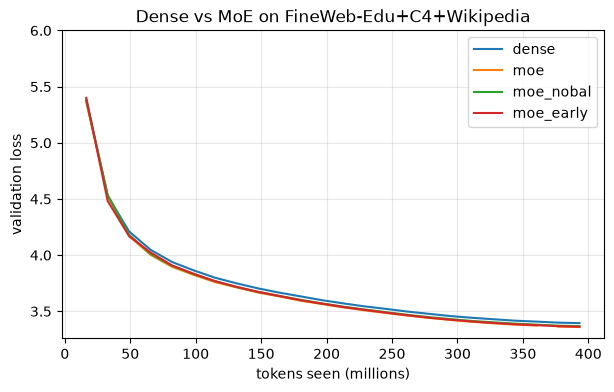

,run,finished,steps,best_val_loss,perplexity,final_aux_loss,tokens_per_s
0,dense,True,6000,3.3950,29.82,NaN,18209
1,moe,True,6000,3.3600,28.79,1.01080,17793
2,moe_nobal,True,6000,3.3680,29.02,1.90089,16916
3,moe_early,True,6000,3.3628,28.87,0.99894,17809


In [11]:
import pandas as pd, matplotlib.pyplot as plt, math, os
R = '/content/drive/MyDrive/nova_base/runs'; os.makedirs('/content/drive/MyDrive/nova_base/results', exist_ok=True)
runs = [r for r in ['dense', 'moe', 'moe_nobal', 'moe_seed2', 'moe_early'] if os.path.exists(f'{R}/{r}/log.csv')]
plt.figure(figsize=(7,4)); rows = []
for r in runs:
    log = pd.read_csv(f'{R}/{r}/log.csv')
    plt.plot(log.tokens/1e6, log.val_loss, label=r)
    rows.append({'run': r, 'finished': os.path.exists(f'{R}/{r}/DONE.json'), 'steps': int(log.step.iloc[-1]),
                 'best_val_loss': round(log.val_loss.min(), 4), 'perplexity': round(math.exp(log.val_loss.min()), 2),
                 'final_aux_loss': log.aux_loss.iloc[-1], 'tokens_per_s': int(log.tok_per_s.median())})
plt.xlabel('tokens seen (millions)'); plt.ylabel('validation loss'); plt.legend(); plt.grid(alpha=.3)
plt.title('Dense vs MoE on FineWeb-Edu+C4+Wikipedia'); plt.ylim(top=6)
plt.savefig('/content/drive/MyDrive/nova_base/results/val_loss_dense_vs_moe.png', dpi=150, bbox_inches='tight'); plt.show()
pd.DataFrame(rows)

## Routing statistics
`load_cv` measures uneven expert use (0 = perfectly even), `norm_margin_median` how decisively tokens are routed, and `frac_near_tie` the share of tokens whose second and third expert scores are almost equal. Balancing keeps load even but creates more near-ties (25% vs 13% in the first MoE layer); without balancing, one expert in layer 2 is almost never used.

In [12]:
import os, subprocess
names = [n for n in ['moe', 'moe_nobal', 'moe_early'] if os.path.exists('/content/drive/MyDrive/nova_base/runs/' + n + '/DONE.json')]
print('finished MoE runs analysed:', names)
ckpts = ' '.join('/content/drive/MyDrive/nova_base/runs/' + n + '/ckpt_last.pt' for n in names)
nm = ' '.join(names)
import pandas as pd
if names:
    subprocess.run(f'python routing_analysis.py --data_dir /content/drive/MyDrive/nova_base/data --out_dir /content/drive/MyDrive/nova_base/results --ckpts {ckpts} --names {nm}', shell=True, check=True)
    display(pd.read_csv('/content/drive/MyDrive/nova_base/results/routing_summary.csv'))
else:
    print('No MoE run has finished yet: run this section again when one is done.')

finished MoE runs analysed: ['moe', 'moe_nobal', 'moe_early']


,model,layer,max_load,min_load,load_cv,mean_entropy,raw_margin_median,norm_margin_median,frac_near_tie,mean_token_loss
0,moe,2,0.1312,0.1191,0.0294,1.8966,0.2220,0.2287,0.2530,3.3302
1,moe,6,0.1396,0.1159,0.0625,1.2991,0.4421,0.4649,0.1382,3.3302
2,moe,10,0.1715,0.0985,0.1846,1.5398,0.4026,0.5582,0.1541,3.3302
3,moe_nobal,2,0.2754,0.0000,1.0105,1.2583,0.3869,0.4932,0.1263,3.3402
4,moe_nobal,6,0.2890,0.0227,0.7569,1.2632,0.6080,0.6900,0.1015,3.3402
5,moe_nobal,10,0.4353,0.0040,1.3251,1.2954,1.0959,1.4133,0.0464,3.3402
6,moe_early,0,0.1449,0.1180,0.0672,1.9884,0.2347,0.4305,0.1976,3.3277
7,moe_early,1,0.1343,0.1111,0.0540,1.8603,0.2160,0.2568,0.2507,3.3277
8,moe_early,4,0.1411,0.1132,0.0710,1.3136,0.4519,0.4824,0.1350,3.3277


## Expert load and margin distributions

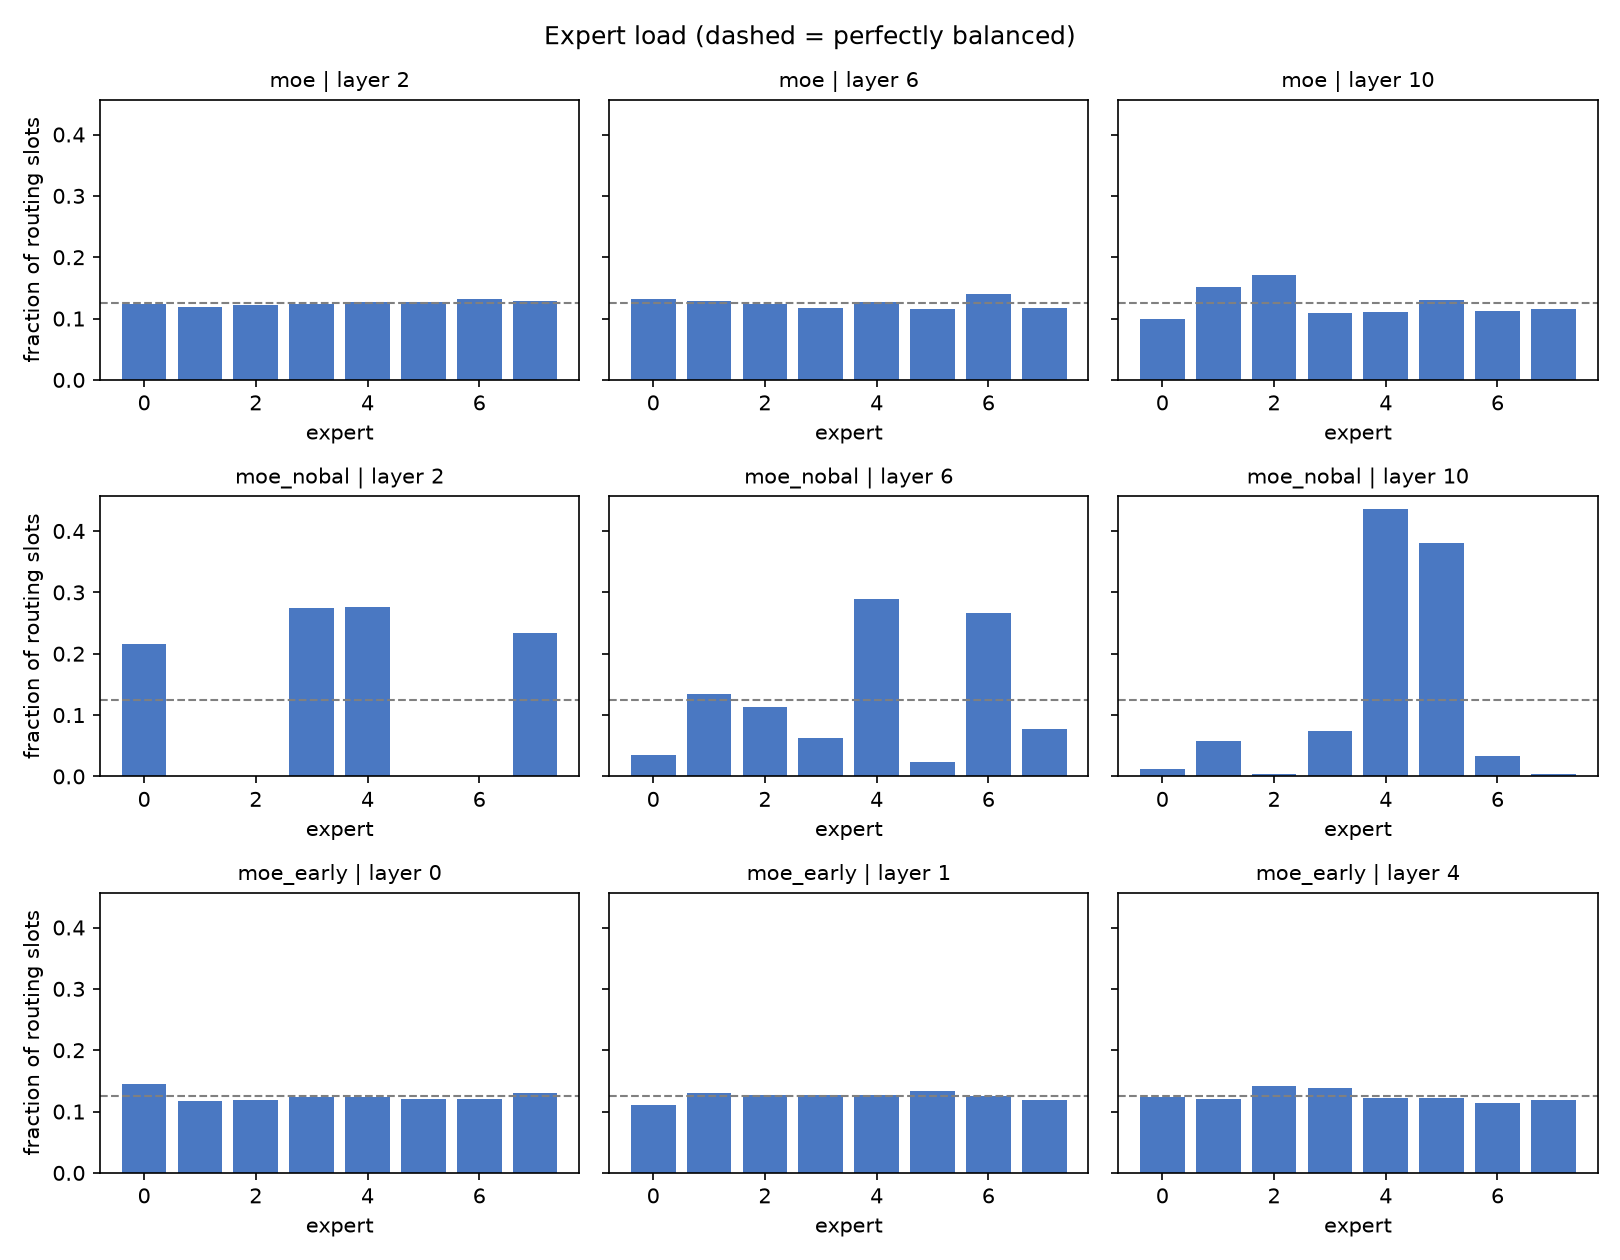

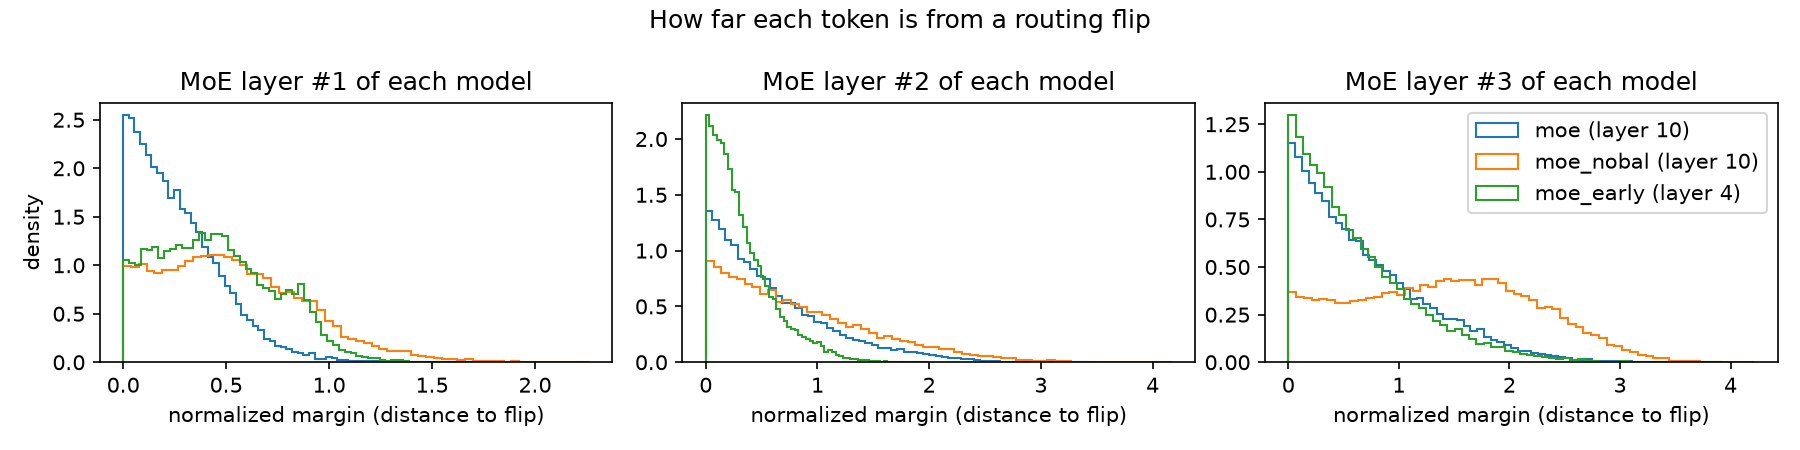

In [13]:
import os
from IPython.display import Image, display
for f in ['expert_load.png', 'margin_hist.png']:
    if os.path.exists('/content/drive/MyDrive/nova_base/results/' + f): display(Image('/content/drive/MyDrive/nova_base/results/' + f))

## Routing by data source
For each MoE layer, the share of routing choices each expert receives within FineWeb-Edu, C4 and Wikipedia tokens. `tv_distance_from_overall` measures how differently a source uses the experts (0 = identical). Differences are small (0.01-0.06) and largest for Wikipedia in the deepest MoE layer, in both placements.

,model,layer,source,tokens,tv_distance_from_overall,top_expert,top_expert_share
0,moe,2,fineweb_edu,15313,0.0102,4,0.1337
1,moe,2,c4,8345,0.0110,3,0.1303
2,moe,2,wikipedia,9110,0.0154,6,0.1358
3,moe,6,fineweb_edu,15313,0.0117,6,0.1430
4,moe,6,c4,8345,0.0240,6,0.1489
5,moe,6,wikipedia,9110,0.0379,0,0.1417
6,moe,10,fineweb_edu,15313,0.0247,2,0.1832
7,moe,10,c4,8345,0.0276,2,0.1651
8,moe,10,wikipedia,9110,0.0609,2,0.1577
9,moe_nobal,2,fineweb_edu,15313,0.0107,3,0.2724


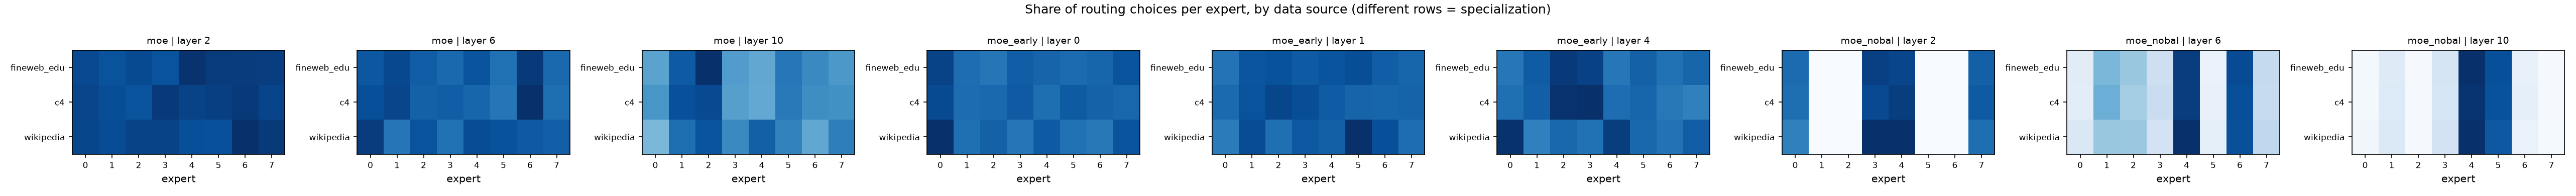

In [14]:
import os, pandas as pd
from IPython.display import Image, display
if os.path.exists('/content/drive/MyDrive/nova_base/results/routing_by_source.csv'):
    bs = pd.read_csv('/content/drive/MyDrive/nova_base/results/routing_by_source.csv')
    display(bs[['model', 'layer', 'source', 'tokens', 'tv_distance_from_overall', 'top_expert', 'top_expert_share']])
    display(Image('/content/drive/MyDrive/nova_base/results/expert_by_source.png'))

## Text samples from the MoE model
Same prompts and sampling settings as B02.

In [15]:
import os, torch
from tokenizers import Tokenizer
from routing_analysis import load_model
tok = Tokenizer.from_file('/content/drive/MyDrive/nova_base/data/tokenizer.json'); eot = tok.token_to_id('<|endoftext|>')
if os.path.exists('/content/drive/MyDrive/nova_base/runs/moe/DONE.json'):
    model = load_model('/content/drive/MyDrive/nova_base/runs/moe/ckpt_last.pt', 'cuda')
    for prompt in ['The history of the city began', 'Scientists have discovered that', 'If you want to improve your writing,']:
        idx = torch.tensor([tok.encode(prompt).ids], device='cuda')
        out = model.generate(idx, 200, temperature=0.8, top_k=50, eot_id=eot)
        print(tok.decode(out[0].tolist()), '\n' + '-'*80)
else:
    print('runs/moe has not finished yet.')

The history of the city began with the arrival of the British in 1511. The city was to be known as The House of Kings and as the residence of the Kings in 1516. The following year, a new residence was called The Lodge, and on October 4, 1516, King Henry of England made the first meeting of his family. The Lodge was then called The House of Kings. It was in the house of King Henry when his wife died.

In the 18th and 19th centuries, many buildings were built to house a large number of households. The first house of royalty was The House of Kings. The house of the King was named after Thomas Aquinas, son of John Aquinas. Aquinas was born in 1619, and was the mother of George Aquinas. His mother, Elizabeth Aquinas, was the first wife of Thomas Aquinas.

Civil War
In 1865, the country came to an end. The colon 
--------------------------------------------------------------------------------
Scientists have discovered that even the biggest, mysterious species, the giant ants, such as the gi